# Entrega 2: preparación de datos y baselines

**TP Integrador de Aprendizaje Automático**

Proyecto: rendimiento de cultivos por partido en la Provincia de Buenos Aires.

Este notebook ejecuta, desde cero:

1. La descarga y verificación del CSV oficial.
2. La limpieza y el registro de exclusiones.
3. El cálculo del promedio de las cinco campañas anteriores.
4. La construcción del rendimiento relativo y de la clase `campaña mala`.
5. El análisis de distribuciones y de los ratios extremos.
6. La justificación del umbral.
7. El split temporal.
8. Los baselines `Dummy` y `promedio de 5 campañas`.
9. El control de las variables climáticas unidas al dataset.

La fuente es pública y tiene licencia CC BY 4.0.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

from src.config import (
    CROPS,
    DATASET_MODELADO,
    DATASET_MODELADO_CLIMA,
    FIGURAS_DIR,
    RATIO_EXTREMO,
    START_YEAR,
    END_YEAR,
    TEST_START,
    THRESHOLD,
    TRAIN_END,
    VALIDATION_END,
)
from src.descargar_datos import download
from src.preparar_datos import (
    read_raw,
    clean_raw,
    build_datasets,
    class_summaries,
    extreme_ratio_cases,
)
from src.baselines import regression_metrics, run_baselines

# src.baselines fija el backend Agg para correr por consola; en el notebook se
# vuelve al backend inline para que las figuras se vean.
%matplotlib inline

# Colores fijos: cada split y cada cultivo conserva su color en todas las figuras.
COLOR_SPLIT = {"train": "#2a78d6", "validacion": "#eb6834", "test": "#1baf7a"}
COLOR_CULTIVO = dict(zip(CROPS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
SPLITS = ["train", "validacion", "test"]

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

print("Raíz del proyecto:", ROOT)
print("Cultivos:", CROPS)

Raíz del proyecto: C:\Users\ASUS\OneDrive\Escritorio\Cursada\aprendizaje automático\TP Integrador
Cultivos: ['Maíz', 'Trigo total', 'Girasol', 'Soja total']


## 1. Fuente y descarga

El archivo se descarga del catálogo de Datos Abiertos de la Provincia de Buenos Aires. Si ya existe localmente, se reutiliza y se verifica su metadata.


In [2]:
raw_path = download()
print(raw_path)


Archivo existente: C:\Users\ASUS\OneDrive\Escritorio\Cursada\aprendizaje automático\TP Integrador\datos\raw\estimaciones-agricolas-1969_2026.csv
{
  "fuente": "https://catalogo.datos.gba.gob.ar/dataset/estimaciones-agro",
  "url_descarga": "https://catalogo.datos.gba.gob.ar/dataset/4ee50a8f-6866-4191-9bf8-aebb30b0d718/resource/d3e23031-164a-43e0-b104-01ced63e4abd/download/estimaciones-agricolas-1969_2026.csv",
  "licencia": "CC BY 4.0",
  "archivo": "estimaciones-agricolas-1969_2026.csv",
  "bytes": 2959265,
  "sha256": "a3b8e1295978343847324b2c3dff4d41b985f093372b34b1290cbc7ad75934e0",
  "filas": 53905,
  "columnas": [
    "cultivo",
    "campania",
    "municipio_id",
    "municipio_nombre",
    "superficie_sembrada",
    "superficie_cosechada",
    "produccion",
    "rendimiento"
  ],
  "descargado_utc": "2026-10-20T21:20:24+00:00"
}
C:\Users\ASUS\OneDrive\Escritorio\Cursada\aprendizaje automático\TP Integrador\datos\raw\estimaciones-agricolas-1969_2026.csv


## 2. Lectura y exploración inicial

La unidad de análisis es **partido × cultivo × campaña**. La variable numérica es el rendimiento en kg/ha.


In [3]:
raw = read_raw()
print("Filas:", len(raw))
print("Columnas:", list(raw.columns))
display(raw.head())
display(raw.dtypes.to_frame("tipo"))


Filas: 53905
Columnas: ['cultivo', 'campania', 'municipio_id', 'municipio_nombre', 'superficie_sembrada', 'superficie_cosechada', 'produccion', 'rendimiento']


,cultivo,campania,municipio_id,municipio_nombre,superficie_sembrada,superficie_cosechada,produccion,rendimiento
0,Ajo,1969/70,6854,25 De Mayo,3,3,10,3333
1,Ajo,1970/71,6854,25 De Mayo,1,1,3,3000
2,Ajo,1969/70,6014,Adolfo Gonzales Chaves,15,15,82,5467
3,Ajo,1970/71,6014,Adolfo Gonzales Chaves,10,10,55,5500
4,Ajo,1971/72,6014,Adolfo Gonzales Chaves,8,8,44,5500


,tipo
cultivo,str
campania,str
municipio_id,int64
municipio_nombre,str
superficie_sembrada,str
superficie_cosechada,str
produccion,str
rendimiento,str


## 3. Limpieza

Se conservan cuatro cultivos: maíz, trigo total, girasol y soja total. Se excluyen sorgo (alta proporción de rendimiento cero) y cebada cervecera (serie corta). También se excluye la campaña 2025/26 por estar incompleta.

Cada exclusión queda registrada en una tabla de auditoría.


In [4]:
limpio_base, registro = clean_raw(raw)
display(registro)
print("Filas después de la limpieza:", len(limpio_base))


,paso,filas_antes,filas_despues,filas_removidas,motivo
0,lectura_csv,53905,53905,0,Archivo original
1,filtrar_cultivos,53905,20495,33410,"Cultivos del alcance: Maíz, Trigo total, Giras..."
2,filtrar_campanias,20495,20393,102,Se conservan campañas 1969 a 2024; se excluye ...
3,quitar_municipio_ignorado,20393,20393,0,Municipio 'Ignorado' sin partido asignado
4,quitar_rendimiento_invalido,20393,20392,1,Rendimiento nulo o negativo
5,quitar_superficie_invalida,20392,20390,2,Superficie sembrada nula o no positiva
6,quitar_duplicados,20390,20390,0,"Duplicados por cultivo, campaña y municipio"
7,ordenar,20390,20390,0,"Orden por cultivo, municipio y campaña"


Filas después de la limpieza: 20390


## 4. Promedio de 5 campañas y objetivos

El promedio se calcula con una grilla calendario: para cada cultivo y municipio se usan las **cinco campañas inmediatamente anteriores**. Si falta un año, el promedio queda nulo y la fila no entra al modelado. Así se evita saltear huecos y se respeta el momento de la predicción.

También se cuenta `prev5_ceros`: cuántas de esas cinco campañas no tuvieron cosecha. Usa solo campañas anteriores, así que está disponible al predecir.

El objetivo de regresión es:

`ratio = rendimiento / promedio_5_campañas_anteriores`

El objetivo de clasificación es:

`campaña_mala = 1 si ratio < 0,85`

La justificación del umbral está en la sección 7.

In [5]:
limpio, modelado = build_datasets(limpio_base)
print("Filas en el dataset limpio:", len(limpio))
print("Filas en el dataset de modelado:", len(modelado))
display(modelado.head())
display(modelado[["rendimiento", "prev5", "prev5_ceros", "ratio", "mala85"]].astype(float).describe().T.round(3))

Filas en el dataset limpio: 20390
Filas en el dataset de modelado: 15179


,cultivo,campania,municipio_id,municipio_nombre,superficie_sembrada,superficie_cosechada,produccion,rendimiento,campania_inicio,campania_fin,perdida_total,peso_superficie,prev5,prev5_ceros,ratio,mala80,mala85,mala90,split
0,Girasol,1981/82,6007,Adolfo Alsina,28000.0,26700.0,26000.0,974.0,1981,1982,False,28000.0,860.0,0,1.132558,0,0,0,train
1,Girasol,1982/83,6007,Adolfo Alsina,25000.0,24000.0,21600.0,900.0,1982,1983,False,25000.0,904.8,0,0.994695,0,0,0,train
2,Girasol,1983/84,6007,Adolfo Alsina,25000.0,24500.0,24500.0,1000.0,1983,1984,False,25000.0,934.8,0,1.069748,0,0,0,train
3,Girasol,1984/85,6007,Adolfo Alsina,28000.0,28000.0,32000.0,1143.0,1984,1985,False,28000.0,934.8,0,1.222721,0,0,0,train
4,Girasol,1985/86,6007,Adolfo Alsina,52000.0,50000.0,73800.0,1476.0,1985,1986,False,52000.0,1003.4,0,1.470999,0,0,0,train


,count,mean,std,min,25%,50%,75%,max
rendimiento,15179.0,3305.714,2031.031,0.0,1900.000,2664.000,4000.000,11800.000
prev5,15179.0,3180.298,1886.888,180.0,1879.800,2544.800,3835.100,10220.000
prev5_ceros,15179.0,0.020,0.205,0.0,0.000,0.000,0.000,4.000
ratio,15179.0,1.060,0.291,0.0,0.905,1.057,1.208,10.294
mala85,15179.0,0.181,0.385,0.0,0.000,0.000,0.000,1.000


## 5. Distribuciones

Se revisan tres cosas:

1. **El rendimiento absoluto** tiene tendencia: los rendimientos de hoy son mucho más altos que los de 1981. Por eso se modela el ratio y no los kg/ha.
2. **El ratio** está centrado cerca de 1 y su forma cambia entre períodos.
3. **Los predictores** tienen escalas muy distintas. Esto importa para KNN en la Clase 3.

Las figuras muestran test solo para describir el cambio de distribución. Ninguna decisión de esta sección se toma mirando el test.

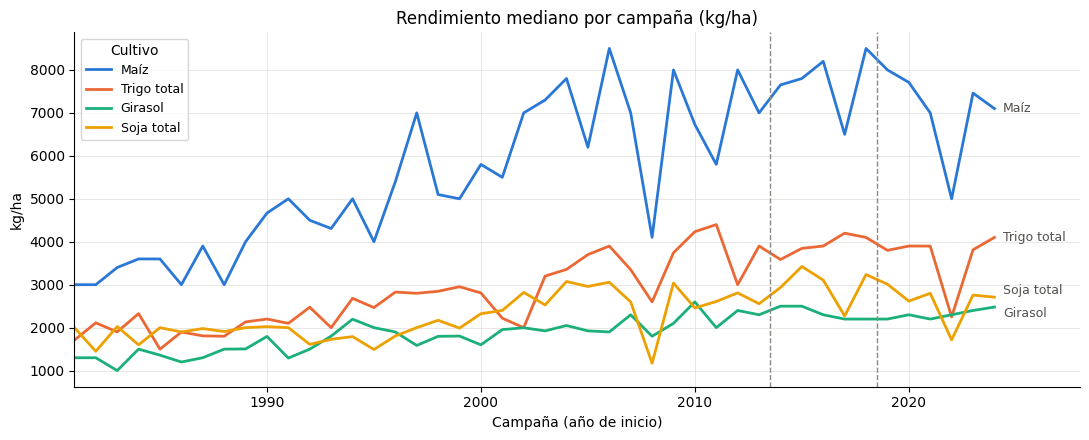

,mediana 1981-1985,mediana 2020-2024,cambio
cultivo,,,
Girasol,1292.0,2336.0,1.81
Maíz,3320.0,6854.0,2.06
Soja total,1815.0,2520.0,1.39
Trigo total,1910.0,3592.0,1.88


In [6]:
mediana = (
    modelado.groupby(["campania_inicio", "cultivo"])["rendimiento"]
    .median()
    .unstack()
)

desplazamiento = {"Soja total": 5, "Girasol": -5}

fig, ax = plt.subplots(figsize=(11, 4.5))
for cultivo in CROPS:
    serie = mediana[cultivo]
    ax.plot(serie.index, serie.values, color=COLOR_CULTIVO[cultivo], linewidth=2, label=cultivo)
    ax.annotate(
        cultivo, (serie.index[-1], serie.values[-1]), xytext=(6, desplazamiento.get(cultivo, 0)),
        textcoords="offset points", va="center", fontsize=9, color="#52514e",
    )
for limite in (TRAIN_END + 0.5, VALIDATION_END + 0.5):
    ax.axvline(limite, color="#8a8984", linewidth=1, linestyle="--")
ax.set_title("Rendimiento mediano por campaña (kg/ha)")
ax.set_xlabel("Campaña (año de inicio)")
ax.set_ylabel("kg/ha")
ax.set_xlim(START_YEAR, END_YEAR + 4)
ax.legend(title="Cultivo", loc="upper left", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "rendimiento_mediano_por_campania.png", dpi=150)
plt.show()

primeros = mediana.loc[START_YEAR:START_YEAR + 4].mean()
ultimos = mediana.loc[END_YEAR - 4:END_YEAR].mean()
display(pd.DataFrame({
    "mediana 1981-1985": primeros.round(0),
    "mediana 2020-2024": ultimos.round(0),
    "cambio": (ultimos / primeros).round(2),
}))

El rendimiento mediano crece en los cuatro cultivos a lo largo de las cuatro décadas. Un modelo que predice kg/ha con datos de 1981-2013 tiene que extrapolar una tendencia que nunca vio en ese rango. El ratio contra el promedio de las cinco campañas anteriores absorbe esa tendencia y la diferencia de suelos entre partidos.

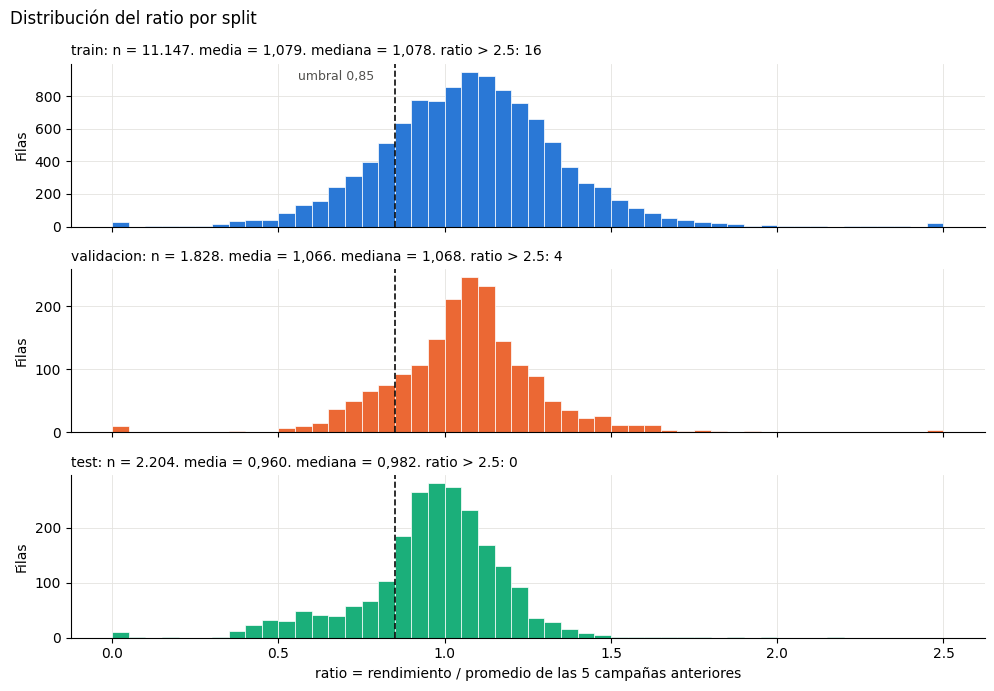

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,11147.0,1.079,0.296,0.0,0.910,1.078,1.238,10.000
validacion,1828.0,1.066,0.316,0.0,0.944,1.068,1.171,10.294
test,2204.0,0.960,0.214,0.0,0.874,0.982,1.086,2.174


In [7]:
bins = np.linspace(0, 2.5, 51)
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, split in zip(axes, SPLITS):
    valores = modelado.loc[modelado["split"] == split, "ratio"]
    fuera = int((valores > bins[-1]).sum())
    ax.hist(valores.clip(upper=bins[-1]), bins=bins, color=COLOR_SPLIT[split], edgecolor="white", linewidth=0.5)
    ax.axvline(THRESHOLD, color="#0b0b0b", linewidth=1.2, linestyle="--")
    ax.set_ylabel("Filas")
    ax.set_title(
        f"{split}: n = {len(valores):,}, media = {valores.mean():.3f}, "
        f"mediana = {valores.median():.3f}, ratio > 2,5: {fuera}"
        .replace(",", "_").replace(".", ",").replace("_", "."),
        fontsize=10, loc="left",
    )
axes[0].annotate("umbral 0,85", (THRESHOLD, axes[0].get_ylim()[1] * 0.9), xytext=(-70, 0),
                 textcoords="offset points", fontsize=9, color="#52514e")
axes[-1].set_xlabel("ratio = rendimiento / promedio de las 5 campañas anteriores")
fig.suptitle("Distribución del ratio por split", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "distribucion_ratio_por_split.png", dpi=150)
plt.show()

display(modelado.groupby("split")["ratio"].describe().loc[SPLITS].round(3))

Lectura:

- En train y validación el ratio está centrado por encima de 1: el promedio de cinco campañas queda rezagado respecto de la tendencia.
- En test la media baja a 0,96 y crece la masa a la izquierda del umbral, sobre todo por la sequía 2022/23. El período de prueba es más difícil que el de entrenamiento.
- La cola derecha es larga: hay pocos casos con ratio mayor a 2,5. Se analizan en la sección 6.
- Las 46 campañas sin cosecha (`perdida_total`) quedan en ratio 0, en el extremo izquierdo. Se conservan.

In [8]:
predictores = ["superficie_sembrada", "prev5", "prev5_ceros", "campania_inicio"]
train = modelado[modelado["split"] == "train"]
display(train[predictores].astype(float).describe().T.round(1))
display(
    train.groupby("cultivo")[["superficie_sembrada", "prev5"]]
    .median()
    .round(0)
    .rename(columns=lambda c: f"mediana {c}")
)

,count,mean,std,min,25%,50%,75%,max
superficie_sembrada,11147.0,23831.4,35059.9,8.0,3300.0,10000.0,30000.0,364791.0
prev5,11147.0,2843.2,1648.0,180.0,1750.8,2260.8,3400.0,9546.6
prev5_ceros,11147.0,0.0,0.2,0.0,0.0,0.0,0.0,4.0
campania_inicio,11147.0,1997.5,9.7,1981.0,1989.0,1998.0,2006.0,2013.0


,mediana superficie_sembrada,mediana prev5
cultivo,,
Girasol,5500.0,1662.0
Maíz,8000.0,4596.0
Soja total,21600.0,2005.0
Trigo total,16500.0,2363.0


Las escalas son muy distintas: la superficie sembrada va de unas pocas hectáreas a más de 300.000, y `prev5` está en miles de kg/ha. KNN usa distancias, así que el `StandardScaler` dentro del Pipeline es obligatorio en la Clase 3. La superficie tiene una cola derecha muy larga; conviene evaluar su logaritmo.

## 6. Ratios extremos

Se revisan las filas con `ratio > 3`, es decir, rendimiento mayor al triple del promedio de las cinco campañas anteriores.

In [9]:
extremos = extreme_ratio_cases(modelado)
print(f"Filas con ratio > {RATIO_EXTREMO}: {len(extremos)}")
display(extremos.round(2))

display(
    modelado.groupby(modelado["prev5_ceros"].rename("ceros en las 5 campañas previas"))["ratio"]
    .describe()[["count", "mean", "50%", "max"]]
    .round(3)
)

Filas con ratio > 3.0: 12


,cultivo,campania,municipio_id,municipio_nombre,superficie_sembrada,prev5,prev5_ceros,rendimiento,ratio,split
0,Maíz,2016/17,6182,Coronel De Marina L Rosales,6800.0,680.0,4,7000.0,10.29,validacion
1,Soja total,1983/84,6595,Olavarria,100.0,180.0,4,1800.0,10.00,train
2,Maíz,2009/10,6056,Bahia Blanca,1200.0,320.0,4,2100.0,6.56,train
3,Maíz,1984/85,6448,Laprida,2000.0,600.0,4,3000.0,5.00,train
4,Soja total,1984/85,6791,Tandil,460.0,360.0,4,1787.0,4.96,train
5,Soja total,1984/85,6595,Olavarria,50.0,360.0,4,1700.0,4.72,train
6,Maíz,2007/08,6182,Coronel De Marina L Rosales,2500.0,420.0,4,1900.0,4.52,train
7,Maíz,2012/13,6056,Bahia Blanca,500.0,1700.0,1,6000.0,3.53,train
8,Maíz,2016/17,6056,Bahia Blanca,4800.0,1880.0,3,6500.0,3.46,validacion
9,Maíz,2011/12,6056,Bahia Blanca,2000.0,1020.0,2,3400.0,3.33,train


,count,mean,50%,max
ceros en las 5 campañas previas,,,,
0,14989.0,1.055,1.056,2.691
1,120.0,1.279,1.301,3.529
2,36.0,1.075,1.216,3.333
3,23.0,1.762,2.254,3.457
4,11.0,4.448,4.722,10.294


Los **12 casos** tienen la misma causa: **una o más campañas sin cosecha entre las cinco anteriores**. Los ceros bajan el promedio y cualquier cosecha normal lo multiplica. Por ejemplo, Coronel de Marina L. Rosales, maíz 2016/17: cuatro de las cinco campañas previas tienen rendimiento 0, el promedio queda en 680 kg/ha y una cosecha de 7.000 kg/ha da un ratio de 10,3.

No son errores de carga: el rendimiento actual es consistente con la producción y la superficie cosechada. Son partidos donde el cultivo era marginal (Bahía Blanca, Coronel Rosales, Laprida, Olavarría, Tandil, Esteban Echeverría) y muchos años se sembraba sin cosechar.

Sin ceros previos, el ratio máximo es 2,69. Con ceros previos, la media sube a 1,48.

**Decisión:**

1. **Se conservan las filas.** El dato es real y eliminarlo sería elegir los casos según el objetivo.
2. **Se agrega `prev5_ceros` como predictor.** Está disponible al predecir y le da al modelo la información para reconocer estos casos.
3. **Se exporta la lista** a `datos/procesado/casos_ratio_extremo.csv`.
4. **No se agrega una columna "es extremo"** al dataset: se calcula con el objetivo y sería fuga si se usara como predictor.
5. **El MAE es la métrica principal de regresión.** Es menos sensible que el RMSE a estos pocos valores grandes.

Las 190 filas con ceros previos son el 1,25% del dataset de modelado. Ninguno de los 12 casos extremos está en test.

In [10]:
media_train = modelado[modelado["split"] == "train"].groupby("cultivo")["ratio"].mean()
validacion = modelado[modelado["split"] == "validacion"].copy()
validacion["pred_dummy"] = validacion["cultivo"].map(media_train)
validacion["pred_prev5"] = 1.0

filas = []
for nombre, subset in {
    "todas las filas": validacion,
    "sin ceros previos": validacion[validacion["prev5_ceros"] == 0],
}.items():
    for modelo, col in {"Dummy": "pred_dummy", "Promedio 5 campañas": "pred_prev5"}.items():
        m = regression_metrics(subset["ratio"], subset[col], subset["prev5"])
        filas.append({"filas": nombre, "modelo": modelo, "n": m["n"],
                      "mae_ratio": m["mae_ratio"], "rmse_ratio": m["rmse_ratio"]})
display(pd.DataFrame(filas).round(4))

,filas,modelo,n,mae_ratio,rmse_ratio
0,todas las filas,Dummy,1828,0.1645,0.3162
1,todas las filas,Promedio 5 campañas,1828,0.1758,0.3229
2,sin ceros previos,Dummy,1799,0.1524,0.2098
3,sin ceros previos,Promedio 5 campañas,1799,0.1631,0.2167


La sensibilidad se calcula en validación. Al quitar las filas con ceros previos, el RMSE baja bastante más que el MAE: unas pocas filas pesan mucho en el error cuadrático. Por eso el informe usa el MAE como métrica principal y reporta el RMSE como complemento.

## 7. Justificación del umbral

La clase positiva es `ratio < 0,85`: una caída de más del 15% respecto del promedio de las cinco campañas anteriores.

Hay dos referencias externas:

- **Ley 26.509 de Emergencia Agropecuaria, artículo 8.** Para acceder a los beneficios, la producción o la capacidad de producción tiene que estar afectada al menos en un 50% (emergencia) o en un 80% (desastre).
- **Seguros multirriesgo.** Suelen garantizar entre el 60% y el 70% del rendimiento promedio de la zona. Pagan cuando el rendimiento cae por debajo de ese nivel.

Ambas referencias marcan pérdidas severas. La alerta del proyecto se usa **antes**, para decidir una cobertura, una venta anticipada o un financiamiento. Por eso tiene que activarse con caídas más moderadas, que ya comprometen el margen.

La tabla calcula la tasa de positivos con distintos umbrales. Usa solo train.

In [11]:
train = modelado[modelado["split"] == "train"]
umbrales = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90]
tabla_umbral = pd.DataFrame({
    "umbral": umbrales,
    "caída mínima": [f"{1 - u:.0%}" for u in umbrales],
    "positivos en train": [int((train["ratio"] < u).sum()) for u in umbrales],
    "tasa en train": [(train["ratio"] < u).mean() for u in umbrales],
})
tabla_umbral["referencia"] = [
    "Ley 26.509: emergencia",
    "",
    "Seguro multirriesgo (60-70%)",
    "Sensibilidad",
    "Umbral principal",
    "Sensibilidad",
]
display(tabla_umbral.round(3))

,umbral,caída mínima,positivos en train,tasa en train,referencia
0,0.50,50%,170,0.015,Ley 26.509: emergencia
1,0.60,40%,386,0.035,
2,0.70,30%,786,0.071,Seguro multirriesgo (60-70%)
3,0.80,20%,1497,0.134,Sensibilidad
4,0.85,15%,2005,0.180,Umbral principal
5,0.90,10%,2643,0.237,Sensibilidad


Lectura:

- Con el umbral de la ley (50%) solo el 1,5% de train es positivo. Son muy pocos casos para aprender, y a esa altura la alerta llega tarde para tomar decisiones de cobertura.
- Con el disparador típico del seguro (70%), la tasa es del 7%.
- Con 85%, la tasa es del 18%: aproximadamente una de cada cinco o seis campañas por partido. Es un evento relevante para el productor y deja suficientes positivos para entrenar.
- El promedio de cinco campañas queda rezagado: el ratio medio en train es 1,08. Una caída del 15% contra ese promedio equivale a cerca del 20% contra el rendimiento esperado actual.

Los umbrales 0,80 y 0,90 quedan como análisis de sensibilidad.

## 8. Balance de clases

La clase positiva es la campaña mala. Un accuracy alto puede esconder un recall nulo: si el 80% de las campañas son normales, un modelo que siempre dice "normal" acierta el 80% y no detecta nada.

In [12]:
by_crop, by_campaign = class_summaries(modelado)
display(by_crop)
display(by_campaign.tail(15))


,cultivo,split,n,positivos,tasa_positivos
0,Girasol,test,451,39,0.086475
1,Girasol,train,2862,450,0.157233
2,Girasol,validacion,413,55,0.133172
3,Maíz,test,606,143,0.235974
4,Maíz,train,3074,560,0.182173
5,Maíz,validacion,499,67,0.134269
6,Soja total,test,568,149,0.262324
7,Soja total,train,2266,380,0.167696
8,Soja total,validacion,451,77,0.170732
9,Trigo total,test,579,139,0.240069


,campania_inicio,split,n,positivos,tasa_positivos
29,2010,train,374,28,0.074866
30,2011,train,375,91,0.242667
31,2012,train,377,72,0.190981
32,2013,train,376,52,0.138298
33,2014,validacion,374,44,0.117647
34,2015,validacion,370,23,0.062162
35,2016,validacion,361,28,0.077562
36,2017,validacion,359,152,0.423398
37,2018,validacion,364,23,0.063187
38,2019,test,370,58,0.156757


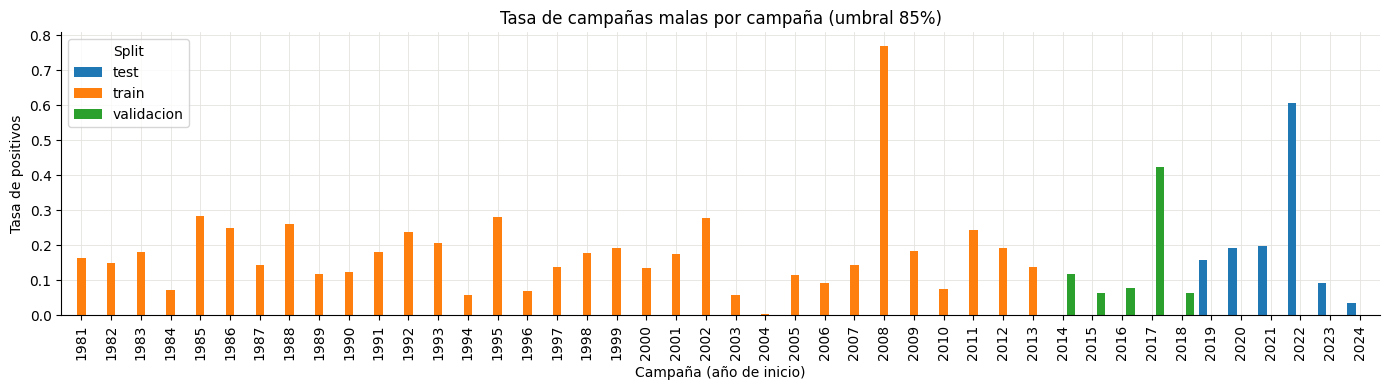

In [13]:
FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

pivot = by_campaign.pivot(index="campania_inicio", columns="split", values="tasa_positivos")
ax = pivot.plot(kind="bar", figsize=(14, 4), width=0.85)
ax.set_title("Tasa de campañas malas por campaña (umbral 85%)")
ax.set_xlabel("Campaña (año de inicio)")
ax.set_ylabel("Tasa de positivos")
ax.legend(title="Split")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "balance_por_campania.png", dpi=150)
plt.show()


## 9. Split temporal

El test se reserva antes de elegir modelos o hiperparámetros:

| Split | Campañas |
|---|---|
| train | 1981/82 a 2013/14 |
| validación | 2014/15 a 2018/19 |
| test | 2019/20 a 2024/25 |

El split es por campaña, no al azar: todos los partidos de una misma campaña comparten el mismo shock climático.

In [14]:
print(f"Train: {START_YEAR} a {TRAIN_END}")
print(f"Validación: {TRAIN_END + 1} a {VALIDATION_END}")
print(f"Test: {TEST_START} a {END_YEAR}")
display(modelado.groupby(["split", "cultivo"]).size().unstack(fill_value=0))


Train: 1981 a 2013
Validación: 2014 a 2018
Test: 2019 a 2024


cultivo,Girasol,Maíz,Soja total,Trigo total
split,,,,
test,451,606,568,579
train,2862,3074,2266,2945
validacion,413,499,451,465


## 10. Baselines

Se comparan dos sistemas:

- **Dummy**: predice la media del ratio del train para cada cultivo. Es el baseline obligatorio de la consigna.
- **Promedio de 5 campañas**: predice `ratio = 1`, es decir, el rendimiento esperado igual al promedio de las cinco campañas anteriores. Es el baseline real del problema.

En clasificación, ambos predicen la clase mayoritaria y, por lo tanto, no generan alertas.

In [15]:
reg, clf, glob = run_baselines(verbose=False)
print("Regresión (test)")
display(reg[reg["split"] == "test"].round(3))
print("Clasificación (test)")
display(clf[clf["split"] == "test"].round(3))
print("Resumen global")
display(glob.round(3))


Regresión (test)


,split,cultivo,modelo,n,mae_ratio,rmse_ratio,r2_ratio,mae_kg,rmse_kg,r2_kg
8,test,Maíz,Dummy,606,0.195,0.275,-0.484,1370.842,1849.774,-0.089
9,test,Maíz,Promedio 5 campañas,606,0.153,0.236,-0.091,1042.169,1502.602,0.282
10,test,Trigo total,Dummy,579,0.196,0.268,-0.293,734.989,1044.152,-0.012
11,test,Trigo total,Promedio 5 campañas,579,0.179,0.240,-0.042,671.859,929.792,0.198
12,test,Girasol,Dummy,451,0.125,0.156,-0.170,279.031,346.974,0.425
13,test,Girasol,Promedio 5 campañas,451,0.112,0.145,-0.019,246.440,314.045,0.529
14,test,Soja total,Dummy,568,0.181,0.243,-0.296,499.275,691.785,-0.166
15,test,Soja total,Promedio 5 campañas,568,0.162,0.219,-0.054,437.690,601.927,0.117


Clasificación (test)


,split,cultivo,modelo,n,accuracy,precision,recall,f1,tp,fp,fn,tn,tasa_alertas
8,test,Maíz,Dummy,606,0.764,0.0,0.0,0.0,0,0,143,463,0.0
9,test,Maíz,Promedio 5 campañas,606,0.764,0.0,0.0,0.0,0,0,143,463,0.0
10,test,Trigo total,Dummy,579,0.760,0.0,0.0,0.0,0,0,139,440,0.0
11,test,Trigo total,Promedio 5 campañas,579,0.760,0.0,0.0,0.0,0,0,139,440,0.0
12,test,Girasol,Dummy,451,0.914,0.0,0.0,0.0,0,0,39,412,0.0
13,test,Girasol,Promedio 5 campañas,451,0.914,0.0,0.0,0.0,0,0,39,412,0.0
14,test,Soja total,Dummy,568,0.738,0.0,0.0,0.0,0,0,149,419,0.0
15,test,Soja total,Promedio 5 campañas,568,0.738,0.0,0.0,0.0,0,0,149,419,0.0


Resumen global


,split,modelo,n,mae_ratio,rmse_ratio,r2_ratio,mae_kg,rmse_kg,r2_kg,clf_n,clf_accuracy,clf_precision,clf_recall,clf_f1,clf_tp,clf_fp,clf_fn,clf_tn,clf_tasa_alertas
0,validacion,Dummy,1828,0.165,0.316,-0.000,620.290,936.049,0.847,1828,0.852,0.0,0.0,0.0,0,0,270,1558,0.0
1,validacion,Promedio 5 campañas,1828,0.176,0.323,-0.043,665.193,947.777,0.843,1828,0.852,0.0,0.0,0.0,0,0,270,1558,0.0
2,test,Dummy,2204,0.177,0.245,-0.313,755.772,1172.683,0.704,2204,0.787,0.0,0.0,0.0,0,0,470,1734,0.0
3,test,Promedio 5 campañas,2204,0.154,0.217,-0.035,626.276,980.542,0.793,2204,0.787,0.0,0.0,0.0,0,0,470,1734,0.0


In [16]:
test_reg = reg[reg["split"] == "test"].copy()
mae = test_reg.pivot(index="cultivo", columns="modelo", values="mae_ratio")
recall = clf[clf["split"] == "test"].pivot(index="cultivo", columns="modelo", values="recall")
display(mae.round(3))
display(recall.round(3))


modelo,Dummy,Promedio 5 campañas
cultivo,,
Girasol,0.125,0.112
Maíz,0.195,0.153
Soja total,0.181,0.162
Trigo total,0.196,0.179


modelo,Dummy,Promedio 5 campañas
cultivo,,
Girasol,0.0,0.0
Maíz,0.0,0.0
Soja total,0.0,0.0
Trigo total,0.0,0.0


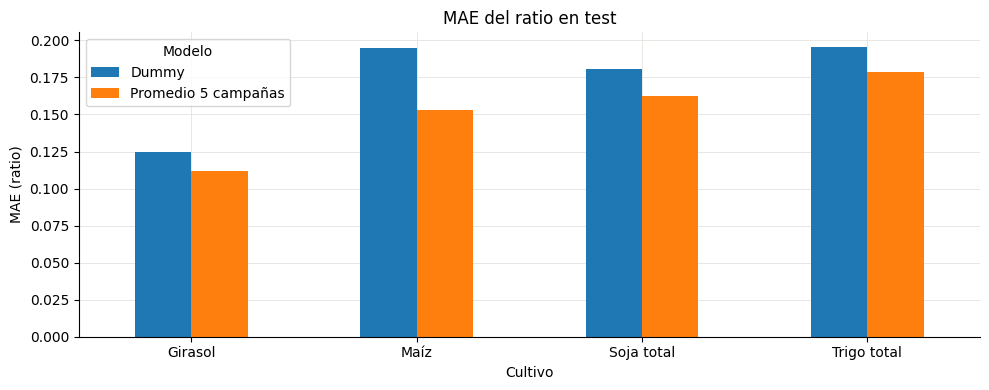

In [17]:
ax = mae.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_title("MAE del ratio en test")
ax.set_ylabel("MAE (ratio)")
ax.set_xlabel("Cultivo")
ax.legend(title="Modelo")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "baselines_mae_ratio_test.png", dpi=150)
plt.show()


## 11. Lectura de los resultados

Los números que importan:

- El **promedio de 5 campañas** tiene un MAE de ratio cercano a 0,15 en test y supera al Dummy, que se queda con la media del train.
- En **validación** el Dummy gana por poco; en **test** pierde. El período de prueba es peor que el de entrenamiento, sobre todo por la sequía 2022/23.
- Ambos baselines tienen **recall = 0**. Aciertan aproximadamente el 79% de las filas y no detectan ninguna campaña mala. Es el ejemplo perfecto de "buen MAE, mala clasificación".
- La campaña **2022/23** concentra alrededor del 61% de los casos malos del test. El modelo de la Clase 3 tiene que demostrar que puede detectarla con clima.

In [18]:
test_2022 = by_campaign[by_campaign["campania_inicio"] == 2022]
display(test_2022)

print("MAE ratio del baseline Promedio 5 en test:",
      round(float(glob[(glob.split == "test") & (glob.modelo == "Promedio 5 campañas")]["mae_ratio"].iloc[0]), 4))
print("Recall del baseline Promedio 5 en test:",
      round(float(glob[(glob.split == "test") & (glob.modelo == "Promedio 5 campañas")]["clf_recall"].iloc[0]), 4))
print("Tasa de positivos en test:", round(float(modelado[modelado.split == "test"]["mala85"].mean()), 4))


,campania_inicio,split,n,positivos,tasa_positivos
41,2022,test,366,222,0.606557


MAE ratio del baseline Promedio 5 en test: 0.1538
Recall del baseline Promedio 5 en test: 0.0
Tasa de positivos en test: 0.2132


## 12. Clima

La descarga de NASA POWER está implementada en `src/clima.py` y se ejecuta una vez, fuera del notebook, porque tarda y depende de la red:

```bash
python -m src.clima --full
python -m src.clima --merge
```

La descarga deja el clima agregado en `datos/procesado/clima_features.csv`, que sí está versionado. El merge lo une al dataset de modelado y genera `datos/procesado/dataset_modelado_con_clima.csv`. Para reproducir esta sección no hace falta descargar nada.

Se controla que la unión no agregue ni pierda filas y que no haya faltantes.

In [19]:
con_clima = pd.read_csv(DATASET_MODELADO_CLIMA, encoding="utf-8")
CLIMA_COLS = [c for c in con_clima.columns if c.startswith("clima_")]

claves = ["cultivo", "campania_inicio", "municipio_id"]
tipos = {"campania_inicio": int, "municipio_id": int}
print("Filas con clima:", len(con_clima), "| filas de modelado:", len(modelado))
print("Mismas filas que el dataset de modelado:",
      con_clima[claves].astype(tipos).reset_index(drop=True)
      .equals(modelado[claves].astype(tipos).reset_index(drop=True)))
print("Faltantes en variables climáticas:", int(con_clima[CLIMA_COLS].isna().sum().sum()))
print("Columnas de fuga presentes:", [c for c in ("produccion", "superficie_cosechada") if c in con_clima])
print("Variables climáticas:", len(CLIMA_COLS))
display(con_clima[con_clima["split"] == "train"][CLIMA_COLS].describe().T.round(1))

Filas con clima: 15179 | filas de modelado: 15179
Mismas filas que el dataset de modelado: True
Faltantes en variables climáticas: 0
Columnas de fuga presentes: []
Variables climáticas: 9


,count,mean,std,min,25%,50%,75%,max
clima_precip_total_mm,11147.0,432.2,137.6,52.5,335.5,422.6,521.0,1018.0
clima_dias_tmax_30,11147.0,32.2,22.8,0.0,8.0,34.0,49.0,98.0
clima_tmax_media_c,11147.0,24.2,4.4,12.2,20.0,25.4,27.4,33.7
clima_tmin_media_c,11147.0,10.8,3.4,2.8,7.8,11.7,13.1,19.3
clima_humedad_media_pct,11147.0,67.0,8.2,39.4,61.5,67.4,72.9,86.1
clima_sequia_max_dias,11147.0,16.5,9.1,5.0,10.0,13.0,20.0,87.0
clima_precip_pre_siembra_mm,11147.0,116.5,71.5,3.8,62.9,106.4,154.8,521.8
clima_dias_helada,11147.0,4.3,7.8,0.0,0.0,0.0,4.0,53.0
clima_dias_lluvia,11147.0,46.1,10.8,16.0,39.0,46.0,54.0,78.0


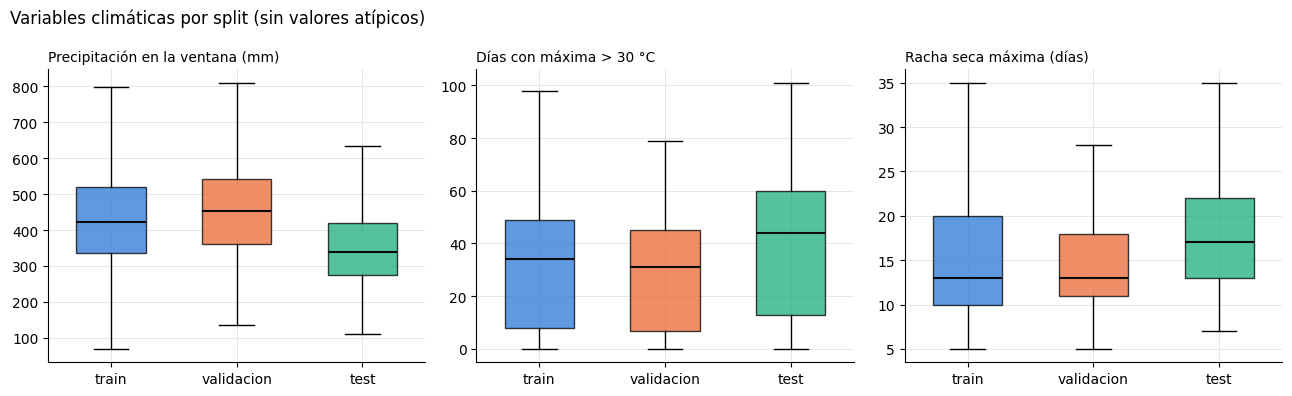

In [20]:
vars_clave = {
    "clima_precip_total_mm": "Precipitación en la ventana (mm)",
    "clima_dias_tmax_30": "Días con máxima > 30 °C",
    "clima_sequia_max_dias": "Racha seca máxima (días)",
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (col, titulo) in zip(axes, vars_clave.items()):
    datos = [con_clima.loc[con_clima["split"] == s, col] for s in SPLITS]
    caja = ax.boxplot(datos, patch_artist=True, widths=0.55, showfliers=False,
                      medianprops={"color": "#0b0b0b", "linewidth": 1.5})
    for parche, split in zip(caja["boxes"], SPLITS):
        parche.set_facecolor(COLOR_SPLIT[split])
        parche.set_alpha(0.75)
    ax.set_xticks(range(1, len(SPLITS) + 1), SPLITS)
    ax.set_title(titulo, fontsize=10, loc="left")
fig.suptitle("Variables climáticas por split (sin valores atípicos)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "clima_por_split.png", dpi=150)
plt.show()

In [21]:
# Correlación de Spearman con el ratio, calculada solo con train.
train_clima = con_clima[con_clima["split"] == "train"]
corr = pd.DataFrame({
    cultivo: train_clima[train_clima["cultivo"] == cultivo][CLIMA_COLS]
    .corrwith(train_clima.loc[train_clima["cultivo"] == cultivo, "ratio"], method="spearman")
    for cultivo in CROPS
})
display(corr.round(2))

,Maíz,Trigo total,Girasol,Soja total
clima_precip_total_mm,0.36,-0.06,0.01,0.42
clima_dias_tmax_30,-0.31,-0.07,0.00,-0.25
clima_tmax_media_c,-0.25,-0.03,-0.03,-0.23
clima_tmin_media_c,-0.13,-0.08,-0.03,-0.03
clima_humedad_media_pct,0.25,-0.05,0.05,0.33
clima_sequia_max_dias,-0.18,-0.13,-0.03,-0.16
clima_precip_pre_siembra_mm,0.19,0.05,-0.00,0.07
clima_dias_helada,0.04,0.06,-0.02,-0.02
clima_dias_lluvia,0.28,0.01,0.03,0.20


Lectura:

- La unión es exacta: 15.179 filas, sin faltantes y sin columnas de fuga.
- El período de test fue más seco y más caluroso: menos precipitación en la ventana, más días con máxima mayor a 30 °C y rachas secas más largas. Es consistente con la caída del ratio medio a 0,96 y con la sequía 2022/23.
- Las correlaciones se calculan solo con train y son exploratorias; la selección de variables se hace con validación en la Clase 3.
- En **maíz y soja** el clima tiene la relación esperada: más lluvia en la ventana se asocia a mejor ratio (+0,36 y +0,42) y más días de calor, a peor ratio (−0,31 y −0,25).
- En **trigo y girasol** las correlaciones son casi nulas. Es una señal de alerta para la Clase 3: con estas variables, el clima puede aportar poco en esos cultivos. Una hipótesis a revisar es que su riesgo dependa de eventos que la ventana agregada no captura bien, como heladas tardías o excesos de agua.
- La relación cambia mucho según el cultivo. Por eso conviene que el modelo vea `cultivo` como predictor o que se entrene un modelo por cultivo.
- Ninguna variable supera 0,42 en valor absoluto. El clima de reanálisis suaviza los extremos locales y la relación con el rendimiento puede no ser lineal.

## 13. Próximos pasos

1. Usar `dataset_modelado_con_clima.csv`, con `prev5_ceros` y las nueve variables climáticas.
2. Entrenar y comparar los regresores obligatorios: Dummy, DecisionTree y KNN con StandardScaler dentro de un Pipeline.
3. Evaluar MAE, RMSE y R², analizar residuos y errores por campaña.
4. Seleccionar el regresor con validación y reservar el test para el final.

## 14. Reproducibilidad

```bash
python -m src.descargar_datos
python -m src.preparar_datos
python -m src.baselines
python -m src.clima --merge
python -m nbconvert --to notebook --execute --inplace notebooks/02_preparacion_y_baselines.ipynb
```